# Titanic - Survival Prediction

**Goal:** predict whether a passenger survived the sinking of the Titanic (`Survived`: 1 = yes, 0 = no) from passenger details, and understand *who* was most likely to survive.

**Dataset:** `train.csv` (891 passengers with the outcome) and `test.csv` (418 passengers without it).

**Type of problem:** binary classification.

**Plan**
1. Load data and check quality
2. Exploratory data analysis
3. Feature engineering (titles, family size, cabin deck ...)
4. Preprocessing pipeline (imputation, scaling, one-hot encoding)
5. Compare several models with cross-validation
6. Tune the best models, evaluate on a held-out validation set
7. Explain the model (feature importance) and predict the test file

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, classification_report)
from sklearn.inspection import permutation_importance

sns.set_theme(style='whitegrid', palette='deep')
RANDOM_STATE = 42

## 1. Load data and check quality

In [2]:
train = pd.read_csv('data/train.csv')
test = pd.read_csv('data/test.csv')
print('Train:', train.shape, '| Test:', test.shape)
train.head()

Train: (891, 12) | Test: (418, 11)

   PassengerId  Survived  Pclass                                               Name     Sex   Age  SibSp  Parch            Ticket     Fare Cabin Embarked
0            1         0       3                            Braund, Mr. Owen Harris    male  22.0      1      0         A/5 21171   7.2500   NaN        S
1            2         1       1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1      0          PC 17599  71.2833   C85        C
2            3         1       3                             Heikkinen, Miss. Laina  female  26.0      0      0  STON/O2. 3101282   7.9250   NaN        S
3            4         1       1       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1      0            113803  53.1000  C123        S
4            5         0       3                           Allen, Mr. William Henry    male  35.0      0      0            373450   8.0500   NaN        S

In [3]:
missing = pd.DataFrame({'train missing': train.isna().sum(), 'train %': (train.isna().mean() * 100).round(1),
                        'test missing': test.isna().sum().reindex(train.columns)})
missing[missing['train missing'] + missing['test missing'].fillna(0) > 0]

          train missing  train %  test missing
Age                 177     19.9          86.0
Fare                  0      0.0           1.0
Cabin               687     77.1         327.0
Embarked              2      0.2           0.0

- **Age** is missing for about 20% of passengers (impute).
- **Cabin** is missing for about 77% (too sparse to use directly, but *whether* a cabin is recorded, and its deck letter, is informative).
- **Embarked** (2 rows in train) and **Fare** (1 row in test) have only a handful of gaps.

In [4]:
print('Duplicate rows:', train.duplicated().sum())
print('Overall survival rate: {:.1%}'.format(train['Survived'].mean()))
train['Survived'].value_counts().rename({0: 'Died', 1: 'Survived'})

Duplicate rows: 0
Overall survival rate: 38.4%

Survived
Died        549
Survived    342
Name: count, dtype: int64

## 2. Exploratory data analysis

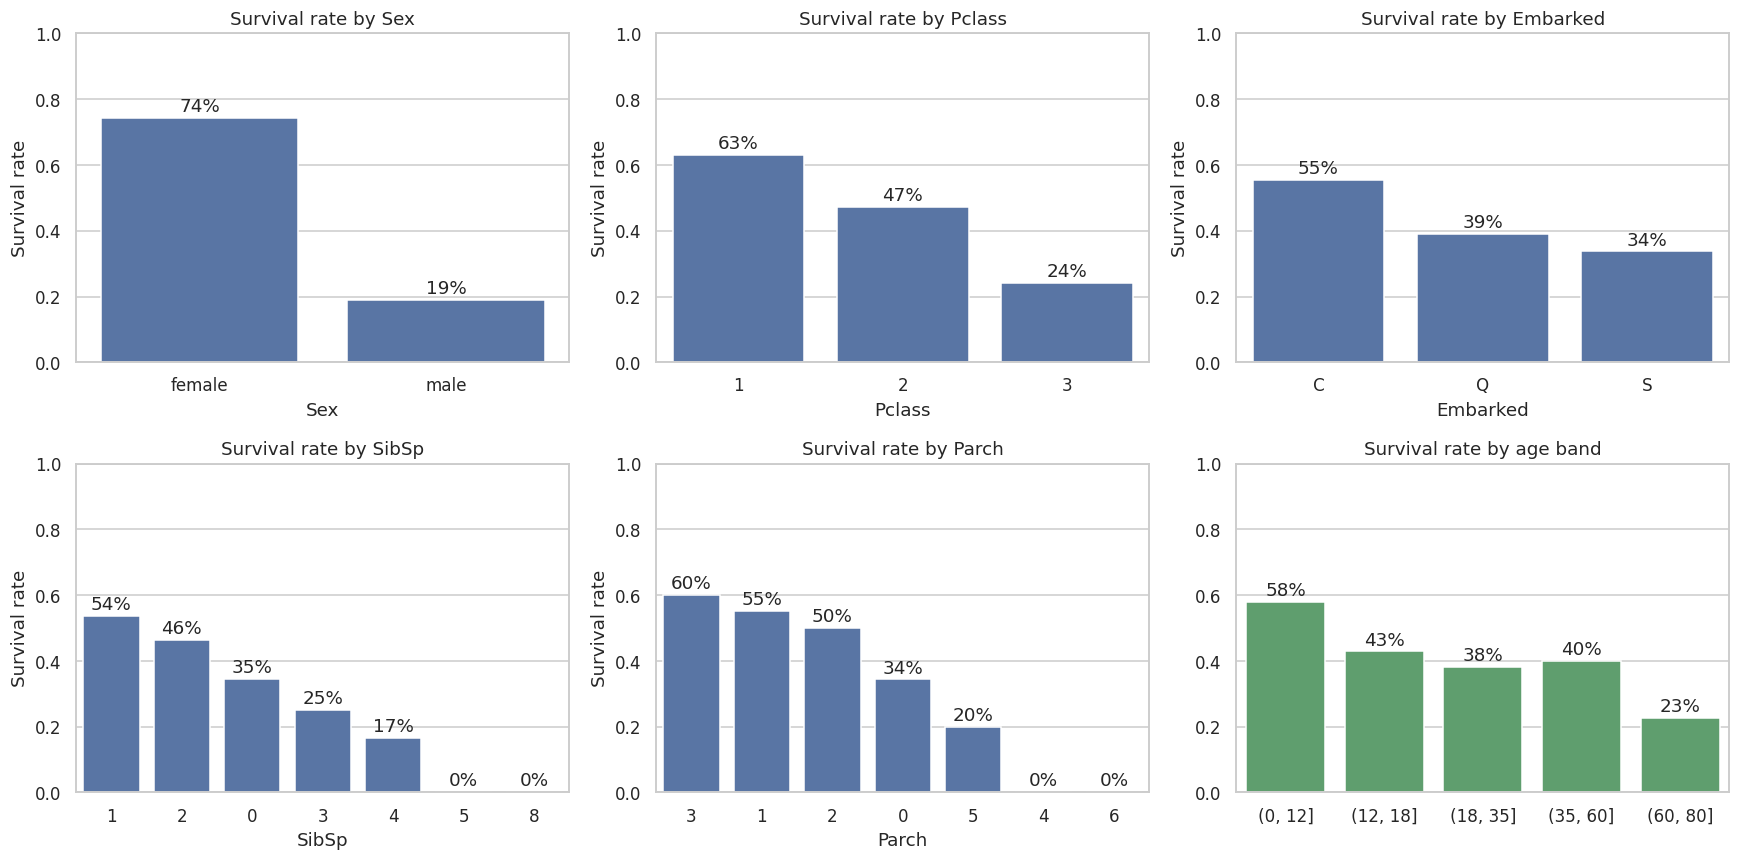

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), ['Sex', 'Pclass', 'Embarked', 'SibSp', 'Parch']):
    rate = train.groupby(col)['Survived'].mean().sort_values(ascending=False)
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax, color='#4C72B0')
    ax.set_title(f'Survival rate by {col}'); ax.set_ylabel('Survival rate'); ax.set_ylim(0, 1)
    for i, v in enumerate(rate.values):
        ax.text(i, v + .02, f'{v:.0%}', ha='center')
rate = train.groupby(pd.cut(train['Age'], [0, 12, 18, 35, 60, 80]))['Survived'].mean()
sns.barplot(x=[str(i) for i in rate.index], y=rate.values, ax=axes[1, 2], color='#55A868')
axes[1, 2].set_title('Survival rate by age band'); axes[1, 2].set_ylim(0, 1)
for i, v in enumerate(rate.values):
    axes[1, 2].text(i, v + .02, f'{v:.0%}', ha='center')
plt.tight_layout()

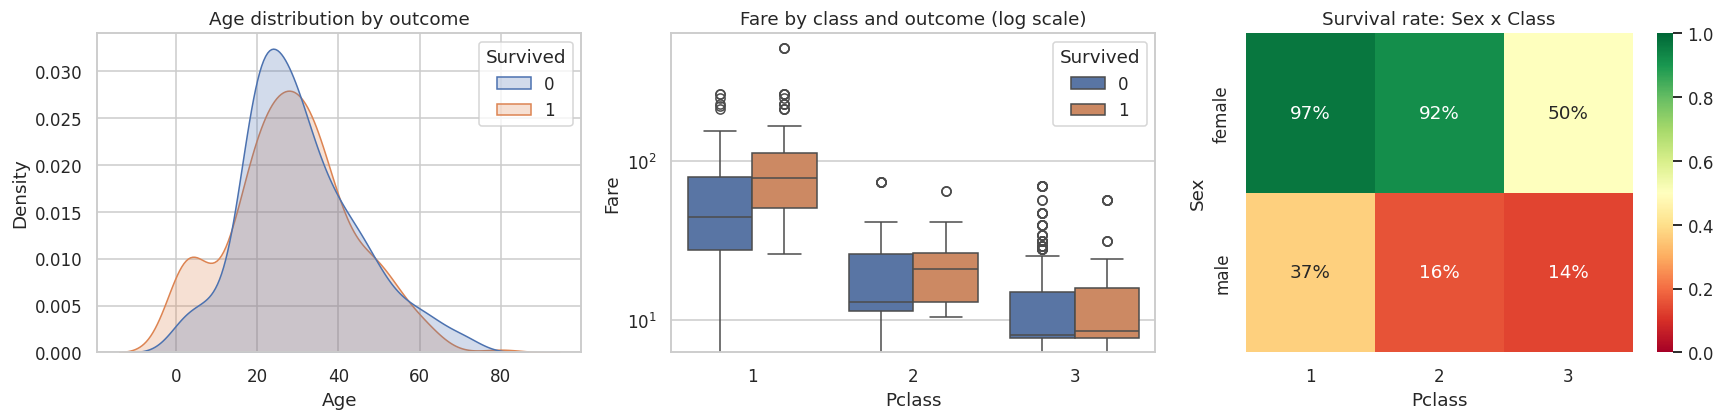

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.kdeplot(data=train, x='Age', hue='Survived', fill=True, common_norm=False, ax=axes[0])
axes[0].set_title('Age distribution by outcome')
sns.boxplot(data=train, x='Pclass', y='Fare', hue='Survived', ax=axes[1])
axes[1].set_yscale('log'); axes[1].set_title('Fare by class and outcome (log scale)')
pivot = train.pivot_table(index='Sex', columns='Pclass', values='Survived', aggfunc='mean')
sns.heatmap(pivot, annot=True, fmt='.0%', cmap='RdYlGn', ax=axes[2], vmin=0, vmax=1)
axes[2].set_title('Survival rate: Sex x Class')
plt.tight_layout()

In [7]:
pivot.round(3)

Pclass      1      2      3
Sex                        
female  0.968  0.921  0.500
male    0.369  0.157  0.135

## 3. Feature engineering
Raw columns hide useful information. We create:
- **Title** from the name (Mr, Mrs, Miss, Master, rare titles) - captures sex, age group and social status
- **FamilySize** = SibSp + Parch + 1 and **IsAlone**
- **HasCabin** and **Deck** (first letter of the cabin)
- **FarePerPerson** - ticket fares are shared by the whole travelling group

In [8]:
def engineer(df):
    d = df.copy()
    d['Title'] = d['Name'].str.extract(r',\s*([^\.]+)\.', expand=False).str.strip()
    d['Title'] = d['Title'].replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs', 'Lady': 'Rare', 'Countess': 'Rare', 'the Countess': 'Rare',
                                     'Capt': 'Rare', 'Col': 'Rare', 'Don': 'Rare', 'Dr': 'Rare', 'Major': 'Rare',
                                     'Rev': 'Rare', 'Sir': 'Rare', 'Jonkheer': 'Rare', 'Dona': 'Rare'})
    d['FamilySize'] = d['SibSp'] + d['Parch'] + 1
    d['IsAlone'] = (d['FamilySize'] == 1).astype(int)
    d['HasCabin'] = d['Cabin'].notna().astype(int)
    d['Deck'] = d['Cabin'].map(lambda c: c[0] if isinstance(c, str) else 'Unknown')
    ticket_size = d.groupby('Ticket')['Ticket'].transform('count')
    d['FarePerPerson'] = d['Fare'] / ticket_size
    return d

train_fe, test_fe = engineer(train), engineer(test)
train_fe[['Name', 'Title', 'FamilySize', 'IsAlone', 'HasCabin', 'Deck', 'FarePerPerson']].head()

                                                Name Title  FamilySize  IsAlone  HasCabin     Deck  FarePerPerson
0                            Braund, Mr. Owen Harris    Mr           2        0         0  Unknown         7.2500
1  Cumings, Mrs. John Bradley (Florence Briggs Th...   Mrs           2        0         1        C        71.2833
2                             Heikkinen, Miss. Laina  Miss           1        1         0  Unknown         7.9250
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)   Mrs           2        0         1        C        26.5500
4                           Allen, Mr. William Henry    Mr           1        1         0  Unknown         8.0500

        mean  count
Title              
Mrs     0.79    126
Miss    0.70    185
Master  0.57     40
Rare    0.35     23
Mr      0.16    517

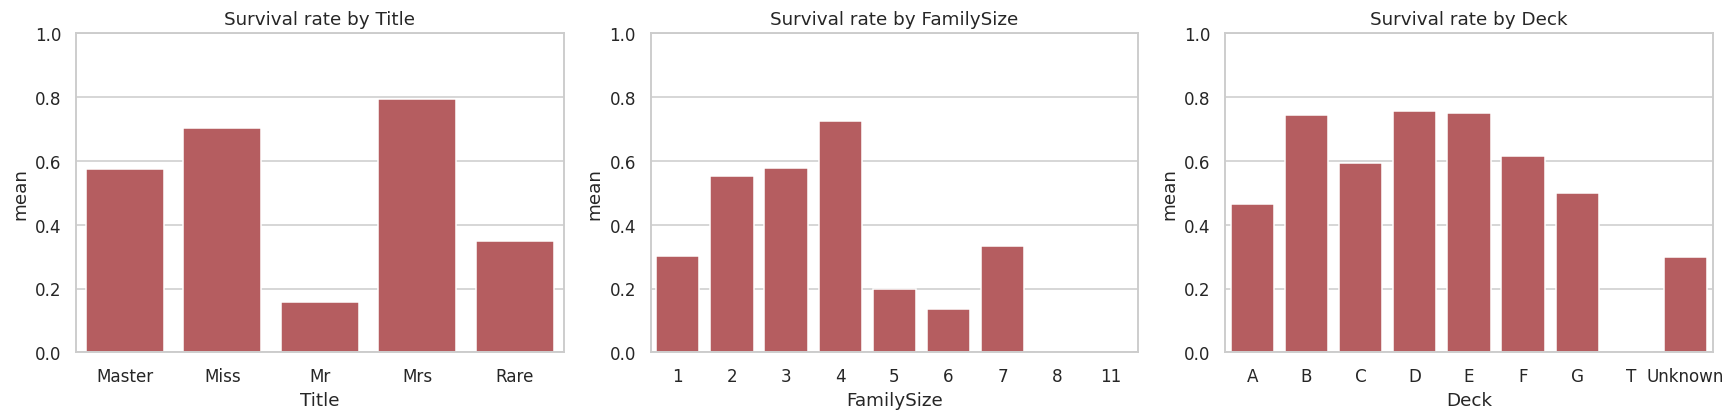

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['Title', 'FamilySize', 'Deck']):
    rate = train_fe.groupby(col)['Survived'].agg(['mean', 'count'])
    sns.barplot(x=rate.index.astype(str), y=rate['mean'], ax=ax, color='#C44E52')
    ax.set_title(f'Survival rate by {col}'); ax.set_ylim(0, 1)
plt.tight_layout()
train_fe.groupby('Title')['Survived'].agg(['mean', 'count']).round(2).sort_values('mean', ascending=False)

## 4. Preprocessing pipeline
Everything (imputation, scaling, encoding) lives inside a scikit-learn `Pipeline`, so it is fitted **only on training folds** - no information leaks from validation data.

In [10]:
numeric = ['Age', 'Fare', 'FarePerPerson', 'FamilySize', 'SibSp', 'Parch', 'IsAlone', 'HasCabin']
categorical = ['Pclass', 'Sex', 'Embarked', 'Title', 'Deck']
features = numeric + categorical

preprocess = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), numeric),
    ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore'))]), categorical),
])

X = train_fe[features]
y = train_fe['Survived']
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print('Training rows:', len(X_train), '| Validation rows:', len(X_val))
print('Survival rate  train: {:.1%}  validation: {:.1%}'.format(y_train.mean(), y_val.mean()))

Training rows: 712 | Validation rows: 179
Survival rate  train: 38.3%  validation: 38.5%

## 5. Compare models with 5-fold cross-validation
All models see exactly the same folds (stratified, so each fold keeps the survival ratio).

In [11]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'KNN': KNeighborsClassifier(n_neighbors=11),
    'SVM (RBF)': SVC(probability=True, random_state=RANDOM_STATE),
    'Naive Bayes': GaussianNB(),
    'Decision Tree': DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
    'Gradient Boosting': GradientBoostingClassifier(random_state=RANDOM_STATE),
}
from sklearn.preprocessing import FunctionTransformer
# GaussianNB needs a dense array, so convert the sparse one-hot output
to_dense = FunctionTransformer(lambda a: a.toarray() if hasattr(a, 'toarray') else a)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, clf in models.items():
    steps = [('prep', preprocess), ('dense', to_dense), ('clf', clf)]
    scores = cross_val_score(Pipeline(steps), X_train, y_train, cv=cv, scoring='accuracy')
    rows.append({'Model': name, 'CV accuracy': scores.mean(), 'Std': scores.std()})
cv_results = pd.DataFrame(rows).sort_values('CV accuracy', ascending=False).set_index('Model')
cv_results.round(4)

                     CV accuracy     Std
Model                                   
Logistic Regression       0.8231  0.0243
SVM (RBF)                 0.8231  0.0202
Random Forest             0.8203  0.0182
Gradient Boosting         0.8203  0.0281
Decision Tree             0.8118  0.0132
KNN                       0.7921  0.0247
Naive Bayes               0.7461  0.1084

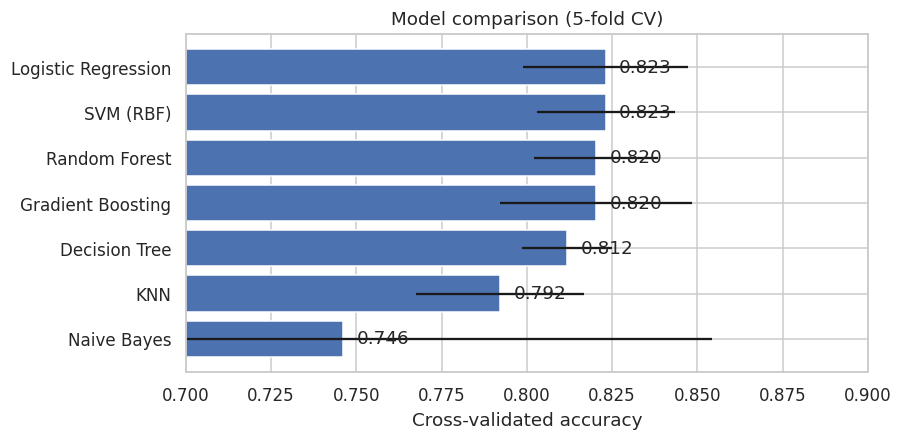

In [12]:
plt.figure(figsize=(8, 4))
order = cv_results.index
plt.barh(order[::-1], cv_results['CV accuracy'][::-1], xerr=cv_results['Std'][::-1], color='#4C72B0')
plt.xlim(0.7, 0.9); plt.xlabel('Cross-validated accuracy'); plt.title('Model comparison (5-fold CV)')
for i, v in enumerate(cv_results['CV accuracy'][::-1]):
    plt.text(v + .004, i, f'{v:.3f}', va='center')

## 6. Hyper-parameter tuning
The best tree-based models get a randomised search over their main settings (scored with cross-validated accuracy on the **training** part only).

In [13]:
search_space = {
    'Random Forest': (RandomForestClassifier(random_state=RANDOM_STATE), {
        'clf__n_estimators': [200, 300, 500], 'clf__max_depth': [3, 4, 5, 6, 8, None],
        'clf__min_samples_leaf': [1, 2, 4, 6], 'clf__max_features': ['sqrt', 0.5, 0.8]}),
    'Gradient Boosting': (GradientBoostingClassifier(random_state=RANDOM_STATE), {
        'clf__n_estimators': [100, 200, 300], 'clf__learning_rate': [0.02, 0.05, 0.1],
        'clf__max_depth': [2, 3, 4], 'clf__subsample': [0.7, 0.85, 1.0], 'clf__min_samples_leaf': [1, 3, 6]}),
}
tuned = {}
for name, (clf, grid) in search_space.items():
    pipe = Pipeline([('prep', preprocess), ('dense', to_dense), ('clf', clf)])
    rs = RandomizedSearchCV(pipe, grid, n_iter=15, cv=cv, scoring='accuracy', random_state=RANDOM_STATE, n_jobs=1)
    rs.fit(X_train, y_train)
    tuned[name] = rs
    print(f'{name}: best CV accuracy = {rs.best_score_:.4f}')
    print('   best params:', {k.replace('clf__', ''): v for k, v in rs.best_params_.items()})

Random Forest: best CV accuracy = 0.8301
   best params: {'n_estimators': 200, 'min_samples_leaf': 2, 'max_features': 0.5, 'max_depth': 3}
Gradient Boosting: best CV accuracy = 0.8315
   best params: {'subsample': 1.0, 'n_estimators': 300, 'min_samples_leaf': 1, 'max_depth': 2, 'learning_rate': 0.1}

## 7. Final evaluation on the held-out validation set
The 20% validation passengers were never used for training or tuning, so these numbers estimate real-world performance.

In [14]:
final_models = {'Logistic Regression': Pipeline([('prep', preprocess), ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]).fit(X_train, y_train),
                'Tuned Random Forest': tuned['Random Forest'].best_estimator_,
                'Tuned Gradient Boosting': tuned['Gradient Boosting'].best_estimator_}
rows = []
for name, m in final_models.items():
    p = m.predict(X_val); proba = m.predict_proba(X_val)[:, 1]
    rows.append({'Model': name, 'Accuracy': accuracy_score(y_val, p), 'Precision': precision_score(y_val, p),
                 'Recall': recall_score(y_val, p), 'F1': f1_score(y_val, p), 'ROC-AUC': roc_auc_score(y_val, proba)})
val_results = pd.DataFrame(rows).set_index('Model')
val_results.round(3)

                         Accuracy  Precision  Recall     F1  ROC-AUC
Model                                                               
Logistic Regression         0.844      0.815   0.768  0.791    0.866
Tuned Random Forest         0.799      0.770   0.681  0.723    0.843
Tuned Gradient Boosting     0.816      0.765   0.754  0.759    0.816

In [15]:
# Choose the final model with CROSS-VALIDATION scores from the training part (not the validation set),
# so the validation numbers above stay an honest, untouched estimate.
cv_scores = {'Logistic Regression': cv_results.loc['Logistic Regression', 'CV accuracy'],
             'Tuned Random Forest': tuned['Random Forest'].best_score_,
             'Tuned Gradient Boosting': tuned['Gradient Boosting'].best_score_}
best_name = max(cv_scores, key=cv_scores.get)
best_model = final_models[best_name]
print('Cross-validated accuracy:', {k: round(v, 4) for k, v in cv_scores.items()})
print('Selected model (highest CV accuracy):', best_name)
print()
print(classification_report(y_val, best_model.predict(X_val), target_names=['Died', 'Survived']))

Cross-validated accuracy: {'Logistic Regression': np.float64(0.8231), 'Tuned Random Forest': np.float64(0.8301), 'Tuned Gradient Boosting': np.float64(0.8315)}
Selected model (highest CV accuracy): Tuned Gradient Boosting

              precision    recall  f1-score   support

        Died       0.85      0.85      0.85       110
    Survived       0.76      0.75      0.76        69

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.82      0.82      0.82       179

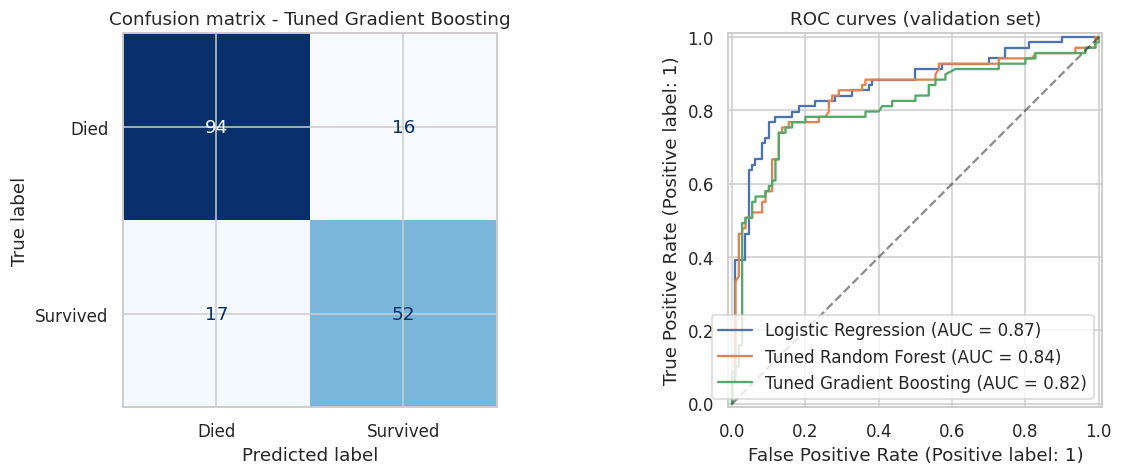

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_estimator(best_model, X_val, y_val, display_labels=['Died', 'Survived'],
                                      cmap='Blues', ax=axes[0], colorbar=False)
axes[0].set_title(f'Confusion matrix - {best_name}')
for name, m in final_models.items():
    RocCurveDisplay.from_estimator(m, X_val, y_val, ax=axes[1], name=name)
axes[1].plot([0, 1], [0, 1], 'k--', alpha=.5); axes[1].set_title('ROC curves (validation set)')
plt.tight_layout()

## 8. What drives survival? (permutation importance)
Permutation importance shuffles one input at a time and measures how much accuracy drops - it works on the original columns, even through one-hot encoding.

Title            0.1335
Sex              0.0816
Fare             0.0646
Age              0.0529
Pclass           0.0337
FarePerPerson    0.0324
FamilySize       0.0212
Embarked         0.0173
SibSp            0.0039
IsAlone          0.0000
Parch            0.0000
Deck            -0.0037
HasCabin        -0.0091
dtype: float64

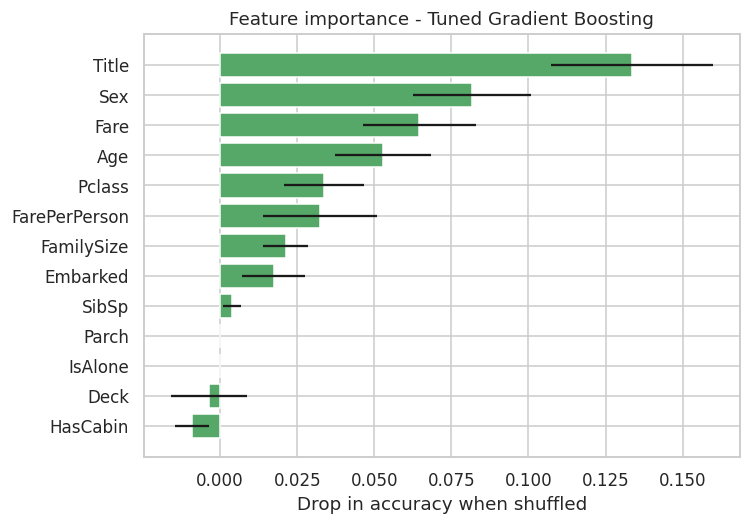

In [17]:
imp = permutation_importance(best_model, X_val, y_val, n_repeats=30, random_state=RANDOM_STATE, scoring='accuracy')
importance = pd.Series(imp.importances_mean, index=X_val.columns).sort_values()
plt.figure(figsize=(7, 5))
plt.barh(importance.index, importance.values, xerr=pd.Series(imp.importances_std, index=X_val.columns)[importance.index], color='#55A868')
plt.xlabel('Drop in accuracy when shuffled'); plt.title(f'Feature importance - {best_name}')
importance.sort_values(ascending=False).round(4)

## 9. Predict the test passengers
The best configuration is retrained on **all 891** labelled passengers and used to predict `test.csv`. (The real outcomes of the test passengers are not public in this dataset, so no score can be computed here.)

In [18]:
final_model = best_model.fit(X, y)
test_pred = final_model.predict(test_fe[features])
submission = pd.DataFrame({'PassengerId': test['PassengerId'], 'Survived': test_pred})
submission.to_csv('titanic_predictions.csv', index=False)
print('Saved titanic_predictions.csv with', len(submission), 'rows')
print('Predicted survival rate on test passengers: {:.1%}'.format(test_pred.mean()))
submission.head()

Saved titanic_predictions.csv with 418 rows
Predicted survival rate on test passengers: 36.1%

   PassengerId  Survived
0          892         0
1          893         0
2          894         0
3          895         0
4          896         1

In [19]:
# Predict one custom passenger
def predict_passenger(**kw):
    row = pd.DataFrame([{'PassengerId': 0, 'Pclass': 3, 'Name': 'Doe, Mr. John', 'Sex': 'male', 'Age': 30, 'SibSp': 0, 'Parch': 0,
                         'Ticket': 'X1', 'Fare': 8.0, 'Cabin': np.nan, 'Embarked': 'S', **kw}])
    p = final_model.predict_proba(engineer(row)[features])[0, 1]
    return f'Survival probability: {p:.0%}'

print('Woman, 1st class, 28:', predict_passenger(Name='Roe, Mrs. Jane', Sex='female', Pclass=1, Age=28, Fare=80.0, Cabin='B20'))
print('Man, 3rd class, 30  :', predict_passenger())
print('Boy, 2nd class, 6   :', predict_passenger(Name='Doe, Master. Tim', Pclass=2, Age=6, Fare=25.0, SibSp=1, Parch=1, Ticket='X2'))

Woman, 1st class, 28: Survival probability: 100%
Man, 3rd class, 30  : Survival probability: 17%
Boy, 2nd class, 6   : Survival probability: 96%

## 10. Conclusions

**What the data says**
- Only **38%** of the passengers in the training data survived.
- Sex and class dominate: about **97%** of 1st-class women and 92% of 2nd-class women survived, versus about **14%** of 3rd-class men (50% of 3rd-class women survived).
- Titles carry extra information beyond sex: *Master* (young boys) survived at 57%, while *Mr* survived at only 16%.

**Model results**
- Seven different models scored between about 0.79 and 0.83 in 5-fold cross-validation (Naive Bayes was clearly weakest). The top four are within one standard deviation of each other, so no model is decisively better; **simple, well-engineered features matter more than the algorithm choice**.
- After tuning, **Gradient Boosting had the best cross-validated accuracy (about 0.83)** and was selected on that basis. On the untouched validation set it reached about **0.82 accuracy** (76% precision and 75% recall for survivors). Logistic Regression scored slightly higher on that single 179-passenger split (0.84), a difference well within random noise.
- The most important inputs are **Title, Sex, Fare, Age and Passenger class**.

**Limitations and next steps**
- Only 891 labelled passengers: results move by a few percentage points with a different split, so rely on the cross-validated numbers.
- `titanic_predictions.csv` has predictions for the 418 test passengers, but their true outcomes are not in this dataset, so the test accuracy is unknown.
- Ideas to improve: group passengers by surname/ticket to model family survival, impute Age by title and class, and combine models (ensembling).